# ELEC5308 — Lab 9: Planning and Decision Making

---

## Overview

In this lab you will work through a **single running example**: a compact weighted road network that represents a stylised city block.
The same world is handed progressively through all four layers of the autonomous-driving hierarchy:

| Layer | Question answered | Section |
|---|---|---|
| **Route planning** | Which sequence of roads minimises travel cost? | 1 |
| **Behaviour planning** | Which atomic manoeuvre should execute next? | 2 |
| **Motion planning** | What is the safest, smoothest physical trajectory? | 3 |
| **Decision under uncertainty** | How does stochastic sensing change the plan? | 4 |

### Mandatory Task (20 marks)
Implement **Dijkstra's algorithm** and **A\* search** inside the scaffold functions in **Section 1**.  
These are autograded via Gradescope.

### Optional Tasks (not marked, highly recommended)
- **Optional A** — Finite-State Machine & rule explosion (Section 2)
- **Optional B** — Trajectory objective function & weight policies (Section 3)
- **Optional C** — MDP value iteration & risk shadows (Section 4)

### Optional Task with Extra Marks
- **Optional D** — Apply a planning algorithm inside `highway-env` and upload a simulation video to Canvas (Section 5)

---

> You are the *supervisor*. Use AI tools to help you write and debug code, but critically verify every output. Ask yourself: *Is this result correct? Why? What would break it?*

---

## ⚙️ Section 0 — Setup & World Definition

Run this cell first. Everything in the lab builds on the graph and helpers defined here.

In [4]:
# ── Core imports ──────────────────────────────────────────────────────────────
import heapq
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')

try:
    import networkx as nx
    HAS_NX = True
except ImportError:
    HAS_NX = False
    print('networkx not found — install with: pip install networkx')

# ── Road network definition ────────────────────────────────────────────────────
#
#  Node coordinates (x, y) in arbitrary map units
#  Think of each node as an intersection in a city block.
#
#       A(0,4)──3──B(2,4)──5──C(5,4)
#       |           |           |
#       4           2           3
#       |           |           |
#       D(0,2)──6──E(2,2)──1──F(5,2)
#       |           |           |
#       5           3           2
#       |           |           |
#       G(0,0)──2──H(2,0)──4──I(5,0)──1──J(7,0)
#
#  Additional shortcut diagonals (representing express roads):
#       A → E : 5   C → F : 4   D → H : 4   E → I : 6

NODE_COORDS = {
    'A': (0, 4), 'B': (2, 4), 'C': (5, 4),
    'D': (0, 2), 'E': (2, 2), 'F': (5, 2),
    'G': (0, 0), 'H': (2, 0), 'I': (5, 0), 'J': (7, 0)
}

# Directed weighted adjacency list  {node: [(neighbour, cost), ...]}
GRAPH = {
    'A': [('B', 3), ('D', 4), ('E', 5)],
    'B': [('A', 3), ('C', 5), ('E', 2)],
    'C': [('B', 5), ('F', 3), ('F', 4)],  # two parallel options → keep lower
    'D': [('A', 4), ('E', 6), ('G', 5), ('H', 4)],
    'E': [('B', 2), ('D', 6), ('F', 1), ('H', 3), ('I', 6)],
    'F': [('C', 3), ('E', 1), ('I', 2)],
    'G': [('D', 5), ('H', 2)],
    'H': [('G', 2), ('D', 4), ('E', 3), ('I', 4)],
    'I': [('H', 4), ('E', 6), ('F', 2), ('J', 1)],
    'J': [('I', 1)]
}

# Canonical start / goal for the mandatory task
START, GOAL = 'A', 'J'

print('Graph loaded — 10 nodes, start =', START, ', goal =', GOAL)

Graph loaded — 10 nodes, start = A , goal = J


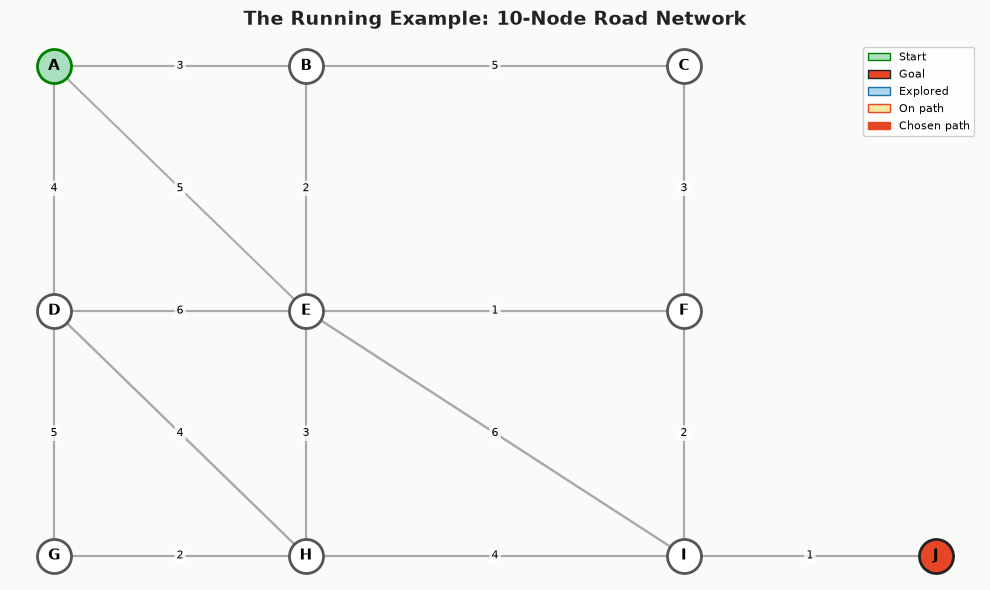

In [5]:
# ── Shared visualisation helpers ───────────────────────────────────────────────

USYD_RED  = '#E64626'
USYD_DARK = '#222222'
PALE_BLUE = '#AED6F1'
PALE_YELL = '#F9E79F'
PALE_GREE = '#A9DFBF'

def draw_graph(
    graph, coords,
    path=None,
    explored=None,
    title='Road Network',
    ax=None,
    show_weights=True,
    node_labels=True
):
    """
    Draw the road network.
    - path      : list of node names forming the chosen route (highlighted red)
    - explored  : set of node names visited by the search algorithm (highlighted blue)
    """
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, 6))

    ax.set_facecolor('#F5F5F0')
    if ax.figure:
        ax.figure.patch.set_facecolor('#FAFAF8')

    explored = explored or set()
    path_edges = set()
    if path:
        path_edges = {(path[i], path[i+1]) for i in range(len(path)-1)}

    # Draw edges
    drawn_pairs = set()
    for u, neighbours in graph.items():
        for v, w in neighbours:
            pair = tuple(sorted([u, v]))
            is_path  = (u, v) in path_edges or (v, u) in path_edges
            color    = USYD_RED  if is_path  else '#AAAAAA'
            lw       = 4.0       if is_path  else 1.5
            zorder   = 3         if is_path  else 1
            x0, y0 = coords[u]
            x1, y1 = coords[v]
            ax.plot([x0, x1], [y0, y1], color=color, lw=lw,
                    solid_capstyle='round', zorder=zorder)
            if show_weights and pair not in drawn_pairs:
                mx, my = (x0+x1)/2, (y0+y1)/2
                ax.text(mx, my, str(w), fontsize=8, ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8),
                        zorder=4)
            drawn_pairs.add(pair)

    # Draw nodes
    for n, (x, y) in coords.items():
        if n == START:
            color, ec = PALE_GREE, 'green'
        elif n == GOAL:
            color, ec = USYD_RED, USYD_DARK
        elif n in explored:
            color, ec = PALE_BLUE, '#2471A3'
        elif path and n in path:
            color, ec = PALE_YELL, USYD_RED
        else:
            color, ec = 'white', '#555555'
        ax.scatter(x, y, s=600, color=color, edgecolors=ec, linewidths=2.0, zorder=5)
        if node_labels:
            ax.text(x, y, n, ha='center', va='center',
                    fontsize=11, fontweight='bold', zorder=6)

    # Legend
    legend_items = [
        mpatches.Patch(color=PALE_GREE,  ec='green',   label='Start'),
        mpatches.Patch(color=USYD_RED,   ec=USYD_DARK, label='Goal'),
        mpatches.Patch(color=PALE_BLUE,  ec='#2471A3', label='Explored'),
        mpatches.Patch(color=PALE_YELL,  ec=USYD_RED,  label='On path'),
        mpatches.Patch(color=USYD_RED,   label='Chosen path')
    ]
    ax.legend(handles=legend_items, loc='upper right', fontsize=8, framealpha=0.9)
    ax.set_title(title, fontsize=14, fontweight='bold', color=USYD_DARK, pad=12)
    ax.axis('off')
    if standalone:
        plt.tight_layout()
        plt.show()

draw_graph(GRAPH, NODE_COORDS, title='The Running Example: 10-Node Road Network')

---
## 📍 Section 1 — Route Planning  *(Mandatory — 20 marks)*

### 1.1  Why naive graph traversal fails

BFS finds a path with the fewest **hops**, not the lowest **cost**.  
The cell below shows the BFS solution alongside the graph — notice how expensive it can be.

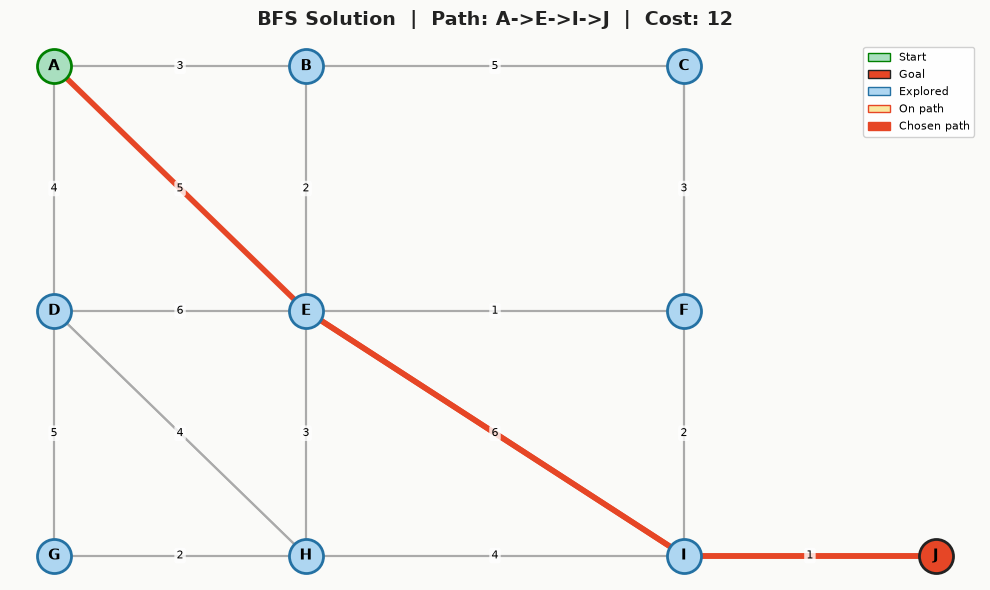

BFS path  : A → E → I → J
BFS cost  : 12  (fewest hops, not minimum cost!)
Nodes explored: ['A', 'B', 'D', 'E', 'C', 'G', 'H', 'F', 'I', 'J']


In [6]:
from collections import deque

def bfs(graph, start, goal):
    """Breadth-First Search — minimises hops, ignores edge weights."""
    queue   = deque([[start]])
    visited = {start}
    explored_order = []
    while queue:
        path = queue.popleft()
        node = path[-1]
        explored_order.append(node)
        if node == goal:
            return path, explored_order
        for neighbour, _ in graph.get(node, []):
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append(path + [neighbour])
    return None, explored_order

def path_cost(graph, path):
    """Return total edge cost of a path (list of node names)."""
    cost_map = {(u, v): w for u, nbrs in graph.items() for v, w in nbrs}
    return sum(cost_map[(path[i], path[i+1])] for i in range(len(path)-1))

bfs_path, bfs_explored = bfs(GRAPH, START, GOAL)
bfs_cost = path_cost(GRAPH, bfs_path)

fig, ax = plt.subplots(figsize=(10, 6))
draw_graph(GRAPH, NODE_COORDS,
           path=bfs_path,
           explored=set(bfs_explored),
           title=f'BFS Solution  |  Path: {"->".join(bfs_path)}  |  Cost: {bfs_cost}',
           ax=ax)
plt.tight_layout()
plt.show()

print(f'BFS path  : {" → ".join(bfs_path)}')
print(f'BFS cost  : {bfs_cost}  (fewest hops, not minimum cost!)')
print(f'Nodes explored: {bfs_explored}')

---
### 1.2  Dijkstra's Algorithm *(10 marks)*

**Idea:** Always expand the node with the smallest accumulated cost `g(n)` using a min-heap.  
This **guarantees the globally optimal path**, but explores in all directions.

$$g(n) = \text{cost from start to } n \quad\quad f(n) = g(n) \quad \text{(no heuristic)}$$

> 🔧 **Your task:** Complete the function below. Do not modify the signature or return type.

In [7]:
def dijkstra(graph, start, goal):
    """
    Find the minimum-cost path from `start` to `goal` using Dijkstra's algorithm.

    Parameters
    ----------
    graph : dict
        {node: [(neighbour, cost), ...]} — directed weighted adjacency list.
    start : str  — source node name.
    goal  : str  — destination node name.

    Returns
    -------
    path     : list of node names from start to goal (inclusive),
               or None if no path exists.
    cost     : float total edge cost of the returned path,
               or float('inf') if no path exists.
    explored : list of node names in the order they were finalised
               (popped from the heap), for visualisation.

    Hint
    ----
    Use heapq.heappush / heappop on a heap whose elements are:
        (accumulated_cost, current_node, path_so_far)
    """
    # ── YOUR CODE BELOW ────────────────────────────────────────────────────────
    heap = [(0, start, [start])]
    finalised = set()
    explored = []
    while heap:
        g, node, path = heapq.heappop(heap)
        if node in finalised:
            continue
        finalised.add(node)
        explored.append(node)
        if node == goal:
            return path, g, explored
        for nbr, w in graph.get(node, []):
            if nbr not in finalised:
                heapq.heappush(heap, (g + w, nbr, path + [nbr]))
    return None, float('inf'), explored
    # ── YOUR CODE ABOVE ────────────────────────────────────────────────────────

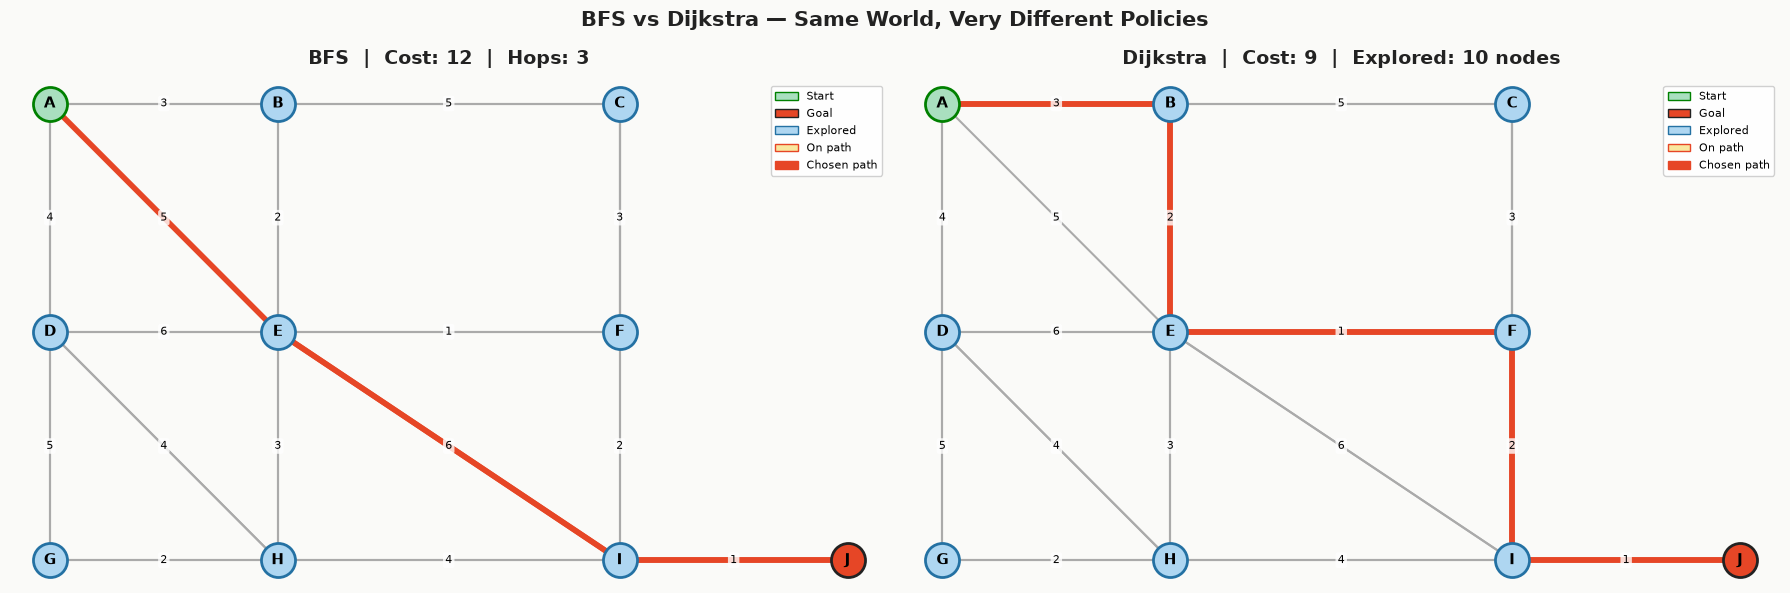

Dijkstra path  : A → B → E → F → I → J
Dijkstra cost  : 9
Nodes explored : ['A', 'B', 'D', 'E', 'F', 'C', 'H', 'I', 'G', 'J']


In [8]:
# ── Smoke-test & visualise ─────────────────────────────────────────────────────
try:
    dij_path, dij_cost, dij_explored = dijkstra(GRAPH, START, GOAL)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    draw_graph(GRAPH, NODE_COORDS,
               path=bfs_path,
               explored=set(bfs_explored),
               title=f'BFS  |  Cost: {bfs_cost}  |  Hops: {len(bfs_path)-1}',
               ax=axes[0])

    draw_graph(GRAPH, NODE_COORDS,
               path=dij_path,
               explored=set(dij_explored),
               title=f"Dijkstra  |  Cost: {dij_cost}  |  Explored: {len(dij_explored)} nodes",
               ax=axes[1])

    plt.suptitle('BFS vs Dijkstra — Same World, Very Different Policies',
                 fontsize=15, fontweight='bold', color=USYD_DARK)
    plt.tight_layout()
    plt.show()

    print(f'Dijkstra path  : {" → ".join(dij_path)}')
    print(f'Dijkstra cost  : {dij_cost}')
    print(f'Nodes explored : {dij_explored}')

except NotImplementedError:
    print('⚠️  Implement dijkstra() above, then re-run this cell.')

---
### 1.3  A\* Search *(10 marks)*

A\* adds a **heuristic** $h(n)$ that estimates the remaining cost to the goal.  
As long as the heuristic is **admissible** (never overestimates), A\* is guaranteed to find the optimal path — while exploring far fewer nodes than Dijkstra.

$$f(n) = \underbrace{g(n)}_{\text{cost so far}} + \underbrace{h(n)}_{\text{estimated remaining}}$$

We provide two ready-to-use heuristics below. You will implement A\* itself.

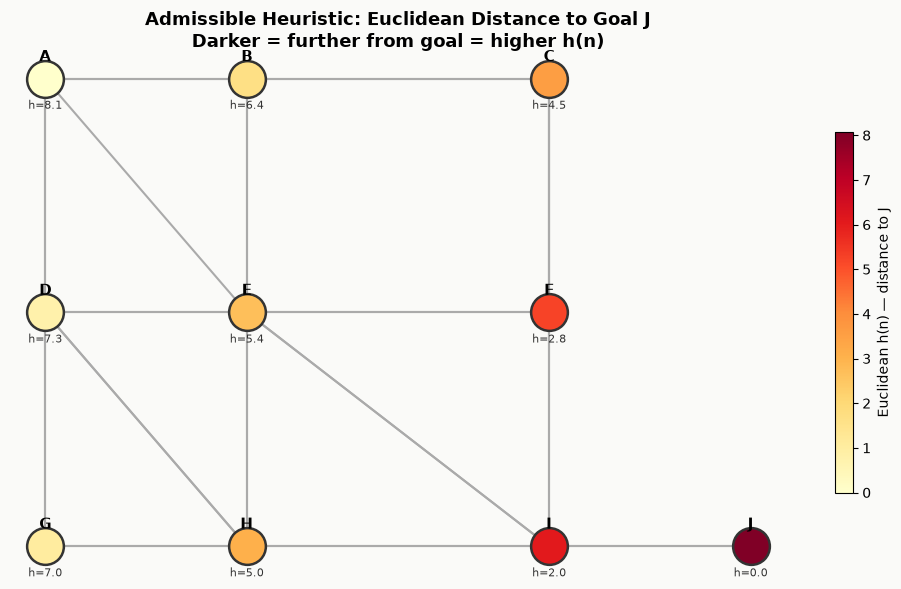

In [9]:
# ── Provided heuristics ────────────────────────────────────────────────────────

def euclidean_heuristic(node, goal=GOAL, coords=NODE_COORDS):
    """Straight-line (Euclidean) distance — always admissible on a road network."""
    x1, y1 = coords[node]
    x2, y2 = coords[goal]
    return math.hypot(x2 - x1, y2 - y1)

def zero_heuristic(node, goal=GOAL, coords=NODE_COORDS):
    """h(n)=0 everywhere → A* degenerates to Dijkstra. Admissible, but uninformative."""
    return 0.0

def inadmissible_heuristic(node, goal=GOAL, coords=NODE_COORDS):
    """5× Euclidean — can overestimate. Finds A path, but not necessarily optimal."""
    return 5 * euclidean_heuristic(node, goal, coords)

# Visualise heuristic values to build intuition
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor('#F5F5F0')
fig.patch.set_facecolor('#FAFAF8')

h_vals = {n: euclidean_heuristic(n) for n in NODE_COORDS}
norm   = mcolors.Normalize(vmin=0, vmax=max(h_vals.values()))
cmap   = plt.cm.YlOrRd

for u, neighbours in GRAPH.items():
    for v, w in neighbours:
        x0,y0 = NODE_COORDS[u]; x1,y1 = NODE_COORDS[v]
        ax.plot([x0,x1],[y0,y1], color='#AAAAAA', lw=1.5, zorder=1)

for n, (x, y) in NODE_COORDS.items():
    h = h_vals[n]
    color = cmap(1 - norm(h))  # high h → darker orange
    ax.scatter(x, y, s=700, color=color, edgecolors='#333', linewidths=1.8, zorder=5)
    ax.text(x, y+0.12, n, ha='center', va='bottom', fontsize=11, fontweight='bold', zorder=6)
    ax.text(x, y-0.18, f'h={h:.1f}', ha='center', va='top', fontsize=8, color='#333', zorder=6)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(vmin=0, vmax=max(h_vals.values())))
plt.colorbar(sm, ax=ax, label='Euclidean h(n) — distance to J', shrink=0.7)
ax.set_title('Admissible Heuristic: Euclidean Distance to Goal J\n'
             'Darker = further from goal = higher h(n)', fontsize=13, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

In [10]:
def a_star(graph, start, goal, heuristic):
    """
    Find the minimum-cost path from `start` to `goal` using A* search.

    Parameters
    ----------
    graph     : dict — {node: [(neighbour, cost), ...]}.
    start     : str  — source node.
    goal      : str  — destination node.
    heuristic : callable — heuristic(node) -> float.
                Must satisfy h(goal) == 0.

    Returns
    -------
    path     : list of node names, or None if unreachable.
    cost     : float total cost, or float('inf').
    explored : list of nodes finalised (popped), for visualisation.

    Hint
    ----
    Heap element: (f_score, g_score, node, path_so_far)
    f = g + h(node)
    """
    # ── YOUR CODE BELOW ────────────────────────────────────────────────────────
    heap = [(heuristic(start), 0, start, [start])]
    best_g = {start: 0}
    finalised = set()
    explored = []
    while heap:
        f, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')):
            continue   # stale entry
        if node not in finalised:
            finalised.add(node)
            explored.append(node)
        if node == goal:
            return path, g, explored
        for nbr, w in graph.get(node, []):
            ng = g + w
            # Re-open nodes when a cheaper route is found, so optimality is
            # preserved even if the heuristic is not consistent.
            if ng < best_g.get(nbr, float('inf')):
                best_g[nbr] = ng
                heapq.heappush(heap, (ng + heuristic(nbr), ng, nbr, path + [nbr]))
    return None, float('inf'), explored
    # ── YOUR CODE ABOVE ────────────────────────────────────────────────────────

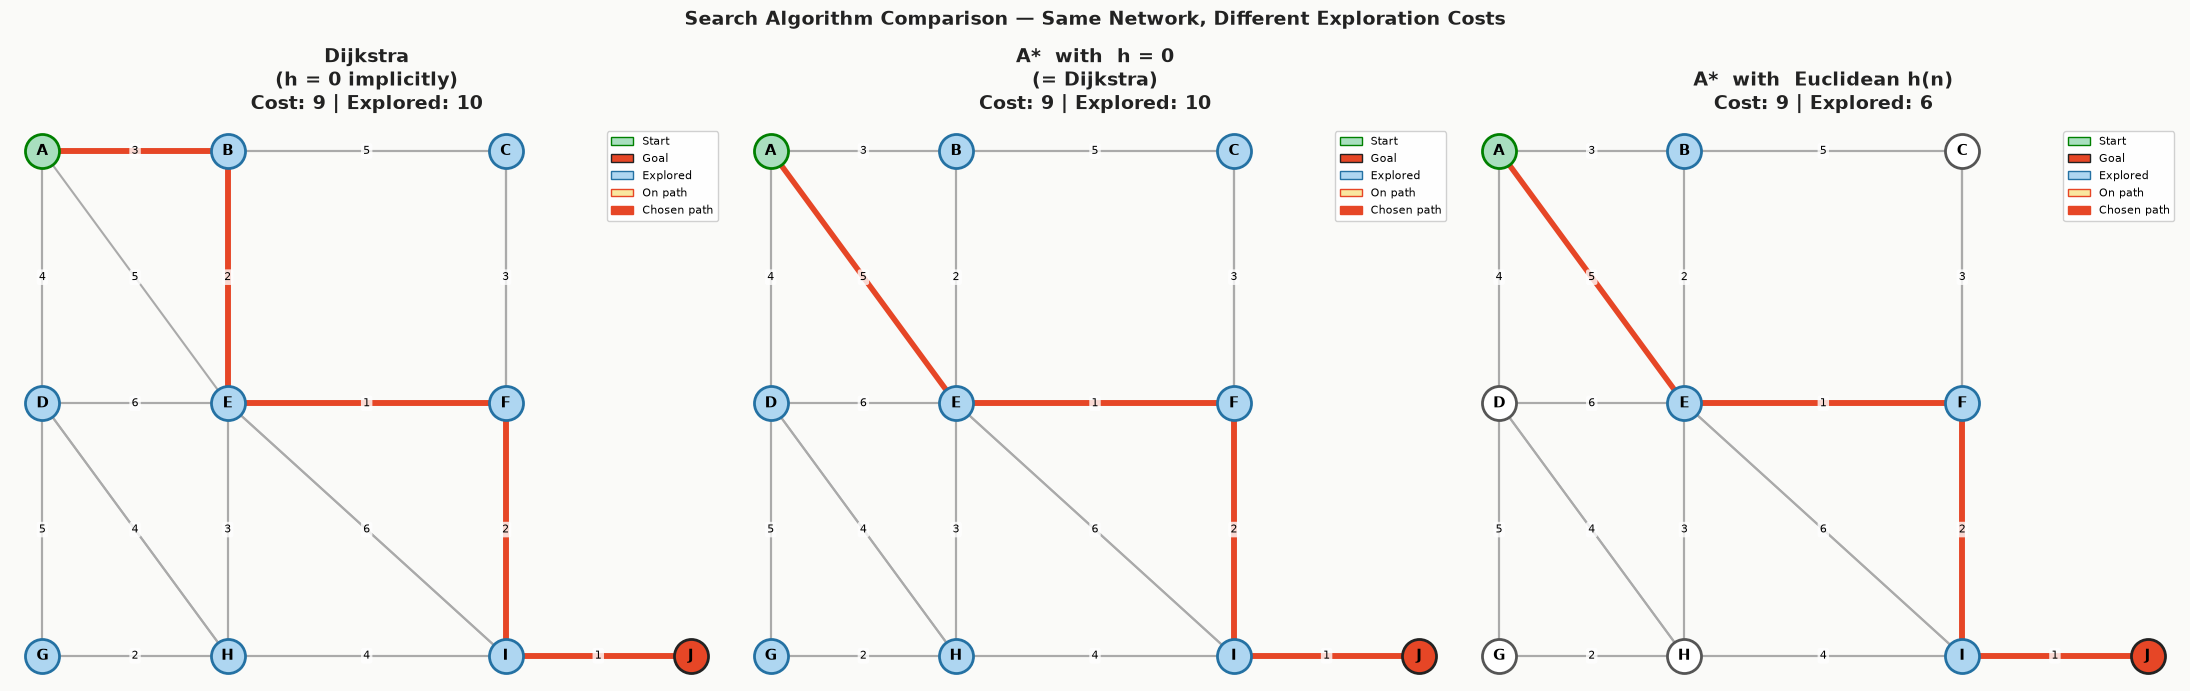

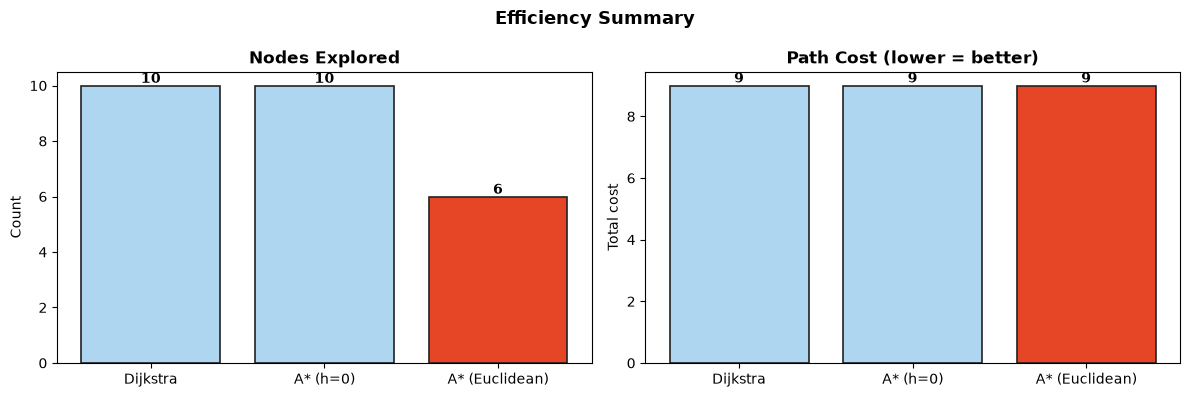

In [11]:
# ── Three-way comparison ───────────────────────────────────────────────────────
try:
    astar_path,  astar_cost,  astar_explored  = a_star(GRAPH, START, GOAL, euclidean_heuristic)
    astar0_path, astar0_cost, astar0_explored = a_star(GRAPH, START, GOAL, zero_heuristic)
    # Re-use Dijkstra result for comparison
    dij_path, dij_cost, dij_explored = dijkstra(GRAPH, START, GOAL)

    fig, axes = plt.subplots(1, 3, figsize=(22, 7))
    configs = [
        (dij_path,   dij_cost,   dij_explored,   'Dijkstra\n(h = 0 implicitly)'),
        (astar0_path, astar0_cost, astar0_explored, 'A*  with  h = 0\n(= Dijkstra)'),
        (astar_path, astar_cost, astar_explored, 'A*  with  Euclidean h(n)'),
    ]
    for ax, (path, cost, explored, title) in zip(axes, configs):
        suffix = f'Cost: {cost} | Explored: {len(explored)}'
        draw_graph(GRAPH, NODE_COORDS,
                   path=path, explored=set(explored),
                   title=f'{title}\n{suffix}', ax=ax)

    plt.suptitle('Search Algorithm Comparison — Same Network, Different Exploration Costs',
                 fontsize=14, fontweight='bold', color=USYD_DARK)
    plt.tight_layout()
    plt.show()

    # Efficiency summary bar chart
    labels   = ['Dijkstra', 'A* (h=0)', 'A* (Euclidean)']
    explored_counts = [len(dij_explored), len(astar0_explored), len(astar_explored)]
    path_costs      = [dij_cost, astar0_cost, astar_cost]

    fig2, (ax_e, ax_c) = plt.subplots(1, 2, figsize=(12, 4))
    colors = [PALE_BLUE, PALE_BLUE, USYD_RED]

    ax_e.bar(labels, explored_counts, color=colors, edgecolor=USYD_DARK, linewidth=1.2)
    ax_e.set_title('Nodes Explored', fontweight='bold')
    ax_e.set_ylabel('Count')
    for i, v in enumerate(explored_counts):
        ax_e.text(i, v + 0.1, str(v), ha='center', fontweight='bold')

    ax_c.bar(labels, path_costs, color=colors, edgecolor=USYD_DARK, linewidth=1.2)
    ax_c.set_title('Path Cost (lower = better)', fontweight='bold')
    ax_c.set_ylabel('Total cost')
    for i, v in enumerate(path_costs):
        ax_c.text(i, v + 0.1, str(v), ha='center', fontweight='bold')

    plt.suptitle('Efficiency Summary', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

except NotImplementedError as e:
    print(f'⚠️  {e}  — implement both dijkstra() and a_star(), then re-run.')

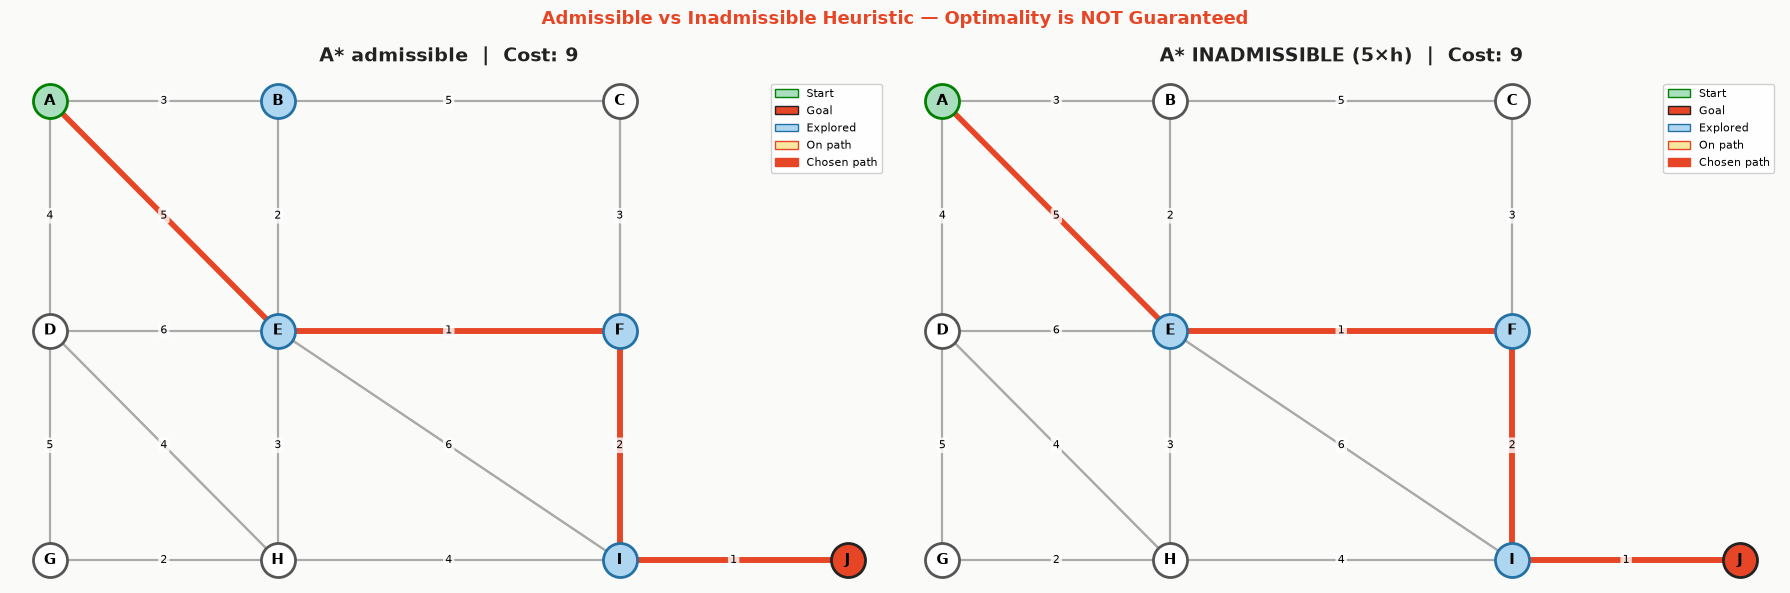

ℹ️  Both found cost 9 on this instance — try a different graph to see failure.


In [12]:
# ── Inadmissible heuristic: what goes wrong? ───────────────────────────────────
try:
    bad_path, bad_cost, bad_explored = a_star(GRAPH, START, GOAL, inadmissible_heuristic)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    draw_graph(GRAPH, NODE_COORDS,
               path=astar_path, explored=set(astar_explored),
               title=f'A* admissible  |  Cost: {astar_cost}', ax=axes[0])
    draw_graph(GRAPH, NODE_COORDS,
               path=bad_path, explored=set(bad_explored),
               title=f'A* INADMISSIBLE (5×h)  |  Cost: {bad_cost}', ax=axes[1])
    plt.suptitle('Admissible vs Inadmissible Heuristic — Optimality is NOT Guaranteed',
                 fontsize=13, fontweight='bold', color=USYD_RED)
    plt.tight_layout()
    plt.show()

    if bad_cost > astar_cost:
        print(f'🚨  Inadmissible heuristic found a SUBOPTIMAL path! Cost {bad_cost} > {astar_cost}')
    else:
        print(f'ℹ️  Both found cost {astar_cost} on this instance — try a different graph to see failure.')

except NotImplementedError:
    print('⚠️  Implement a_star() first.')

### Reflection — Section 1

Answer these in a markdown cell (double-click to edit):

1. How many **fewer** nodes does A* explore compared to Dijkstra on this network? Why?
2. Prove in one sentence that the Euclidean heuristic is admissible for road networks.
3. When would you still prefer Dijkstra over A*?
4. What happens to A*'s explored count if you replace Euclidean distance with Manhattan distance on this network?

**This is a self-reflection unmarked task.**

---

---
## 🚦 Section 2 — Behaviour Planning  *(Optional A — not marked)*

A route plan tells the vehicle **where** to go. The behaviour planner decides **what manoeuvre to execute** at each moment.

We start with a **Finite-State Machine (FSM)** — the workhorse of real-world autonomous systems — then expose its key limitation.

In [13]:
# ── FSM definition ─────────────────────────────────────────────────────────────

from enum import Enum, auto

class State(Enum):
    TRACK_SPEED = auto()   # cruising at target speed
    DECELERATE  = auto()   # slowing for upcoming stop
    STOPPED     = auto()   # at rest, waiting to proceed
    YIELD       = auto()   # ← Optional A: add a Yield state for pedestrians

# Transition table: {(current_state, event): next_state}
TRANSITIONS = {
    (State.TRACK_SPEED, 'stop_line_detected') : State.DECELERATE,
    (State.TRACK_SPEED, 'pedestrian_detected'): State.YIELD,
    (State.DECELERATE,  'velocity_zero')       : State.STOPPED,
    (State.DECELERATE,  'pedestrian_detected') : State.YIELD,
    (State.STOPPED,     'intersection_clear')  : State.TRACK_SPEED,
    (State.YIELD,       'pedestrian_cleared')  : State.TRACK_SPEED,
    (State.YIELD,       'stop_line_detected')  : State.DECELERATE,
}

def fsm_step(current_state, event, transitions=TRANSITIONS):
    """
    Execute one FSM transition.
    Returns the next state, or current state if no transition defined.
    """
    key = (current_state, event)
    next_state = transitions.get(key, current_state)
    return next_state

# ── Trace a stop-sign scenario ─────────────────────────────────────────────────
scenario = [
    'stop_line_detected',
    'pedestrian_detected',
    'pedestrian_cleared',
    'stop_line_detected',
    'velocity_zero',
    'intersection_clear',
]

state   = State.TRACK_SPEED
history = [state]
events  = []

for event in scenario:
    prev  = state
    state = fsm_step(state, event)
    history.append(state)
    events.append(event)
    print(f'  {prev.name:15s}  →[{event}]→  {state.name}')

  TRACK_SPEED      →[stop_line_detected]→  DECELERATE
  DECELERATE       →[pedestrian_detected]→  YIELD
  YIELD            →[pedestrian_cleared]→  TRACK_SPEED
  TRACK_SPEED      →[stop_line_detected]→  DECELERATE
  DECELERATE       →[velocity_zero]→  STOPPED
  STOPPED          →[intersection_clear]→  TRACK_SPEED


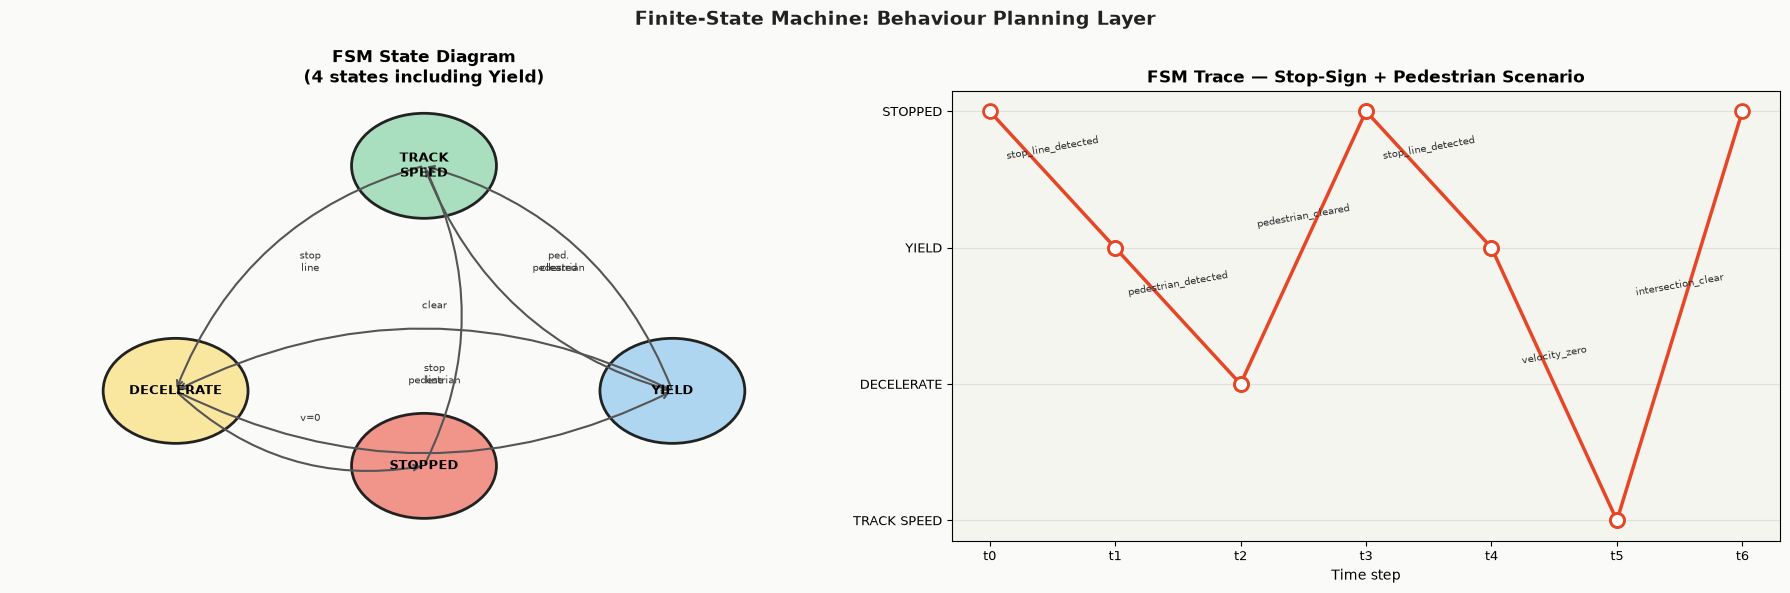

In [14]:
# ── Visualise the FSM state diagram ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# --- Left: FSM graph ---
ax = axes[0]
ax.set_facecolor('#F5F5F0')
fig.patch.set_facecolor('#FAFAF8')
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-0.5, 2.5); ax.axis('off')

state_pos = {
    State.TRACK_SPEED: (1.5, 2.0),
    State.DECELERATE:  (0.3, 0.5),
    State.STOPPED:     (1.5, 0.0),
    State.YIELD:       (2.7, 0.5),
}
state_colors = {
    State.TRACK_SPEED: PALE_GREE,
    State.DECELERATE:  PALE_YELL,
    State.STOPPED:     '#F1948A',
    State.YIELD:       PALE_BLUE,
}
for s, (x, y) in state_pos.items():
    circ = plt.Circle((x, y), 0.35, color=state_colors[s], ec=USYD_DARK, lw=2, zorder=3)
    ax.add_patch(circ)
    label = s.name.replace('_', '\n')
    ax.text(x, y, label, ha='center', va='center', fontsize=9, fontweight='bold', zorder=4)

arrow_props = dict(arrowstyle='->', color=USYD_DARK, lw=1.5,
                   connectionstyle='arc3,rad=0.2')
edge_labels = [
    (State.TRACK_SPEED, State.DECELERATE,  'stop\nline'),
    (State.TRACK_SPEED, State.YIELD,       'pedestrian'),
    (State.DECELERATE,  State.STOPPED,     'v=0'),
    (State.DECELERATE,  State.YIELD,       'pedestrian'),
    (State.STOPPED,     State.TRACK_SPEED, 'clear'),
    (State.YIELD,       State.TRACK_SPEED, 'ped.\ncleared'),
    (State.YIELD,       State.DECELERATE,  'stop\nline'),
]
for src, dst, lbl in edge_labels:
    xs, ys = state_pos[src]
    xd, yd = state_pos[dst]
    ax.annotate('', xy=(xd, yd), xytext=(xs, ys),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.5,
                                connectionstyle='arc3,rad=0.25'))
    mx, my = (xs+xd)/2 + 0.05, (ys+yd)/2 + 0.05
    ax.text(mx, my, lbl, fontsize=7, ha='center', color='#333')

ax.set_title('FSM State Diagram\n(4 states including Yield)', fontsize=12, fontweight='bold')

# --- Right: Trace timeline ---
ax2 = axes[1]
ax2.set_facecolor('#F5F5F0')
state_to_y = {State.TRACK_SPEED: 3, State.DECELERATE: 2, State.YIELD: 1, State.STOPPED: 0}
y_labels   = ['STOPPED', 'YIELD', 'DECELERATE', 'TRACK SPEED']

xs = list(range(len(history)))
ys = [state_to_y[s] for s in history]
for i in range(len(xs)-1):
    ax2.plot([xs[i], xs[i+1]], [ys[i], ys[i+1]], 'o-',
             color=USYD_RED, lw=2.5, markersize=10, markerfacecolor='white',
             markeredgecolor=USYD_RED, markeredgewidth=2)
    mid_x = (xs[i]+xs[i+1])/2
    mid_y = (ys[i]+ys[i+1])/2
    ax2.text(mid_x, mid_y+0.15, events[i], fontsize=7, ha='center', color='#333', rotation=10)

ax2.set_yticks(list(state_to_y.values()))
ax2.set_yticklabels(y_labels, fontsize=9)
ax2.set_xticks(xs)
ax2.set_xticklabels([f't{i}' for i in xs], fontsize=9)
ax2.set_title('FSM Trace — Stop-Sign + Pedestrian Scenario', fontsize=12, fontweight='bold')
ax2.set_xlabel('Time step')
ax2.grid(axis='y', alpha=0.3)
ax2.set_facecolor('#F5F5F0')

plt.suptitle('Finite-State Machine: Behaviour Planning Layer',
             fontsize=14, fontweight='bold', color=USYD_DARK)
plt.tight_layout()
plt.show()

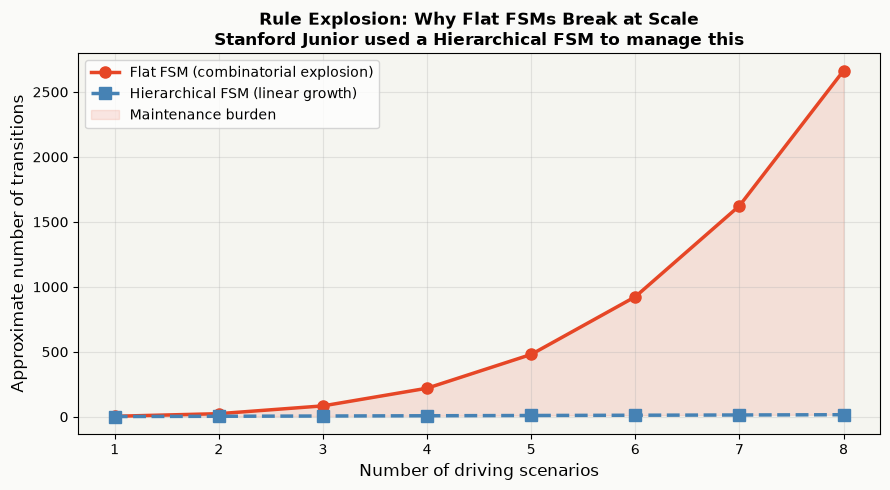


🔧 Optional A Challenge:
Extend TRANSITIONS above with a simultaneous (STOPPED + pedestrian_detected) scenario.
Count how many existing entries you have to touch. That is the maintenance burden.


In [15]:
# ── Optional A Task: Rule explosion visualisation ─────────────────────────────
#
# The plot below shows how the number of required transitions grows as
# new overlapping scenarios are added to a FLAT FSM.

scenarios = list(range(1, 9))
# Flat FSM: each new scenario may interact with all existing state pairs
flat_transitions   = [s * (s - 1) * 2 for s in [2, 4, 7, 11, 16, 22, 29, 37]]
# Hierarchical FSM: superstate grouping limits cross-product growth
hier_transitions   = [s * 2 for s in scenarios]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(scenarios, flat_transitions, 'o-', color=USYD_RED, lw=2.5,
        label='Flat FSM (combinatorial explosion)', markersize=8)
ax.plot(scenarios, hier_transitions, 's--', color='steelblue', lw=2.5,
        label='Hierarchical FSM (linear growth)', markersize=8)
ax.fill_between(scenarios, flat_transitions, hier_transitions,
                alpha=0.12, color=USYD_RED, label='Maintenance burden')
ax.set_xlabel('Number of driving scenarios', fontsize=12)
ax.set_ylabel('Approximate number of transitions', fontsize=12)
ax.set_title('Rule Explosion: Why Flat FSMs Break at Scale\n'
             'Stanford Junior used a Hierarchical FSM to manage this',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.set_facecolor('#F5F5F0')
fig.patch.set_facecolor('#FAFAF8')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('\n🔧 Optional A Challenge:')
print('Extend TRANSITIONS above with a simultaneous (STOPPED + pedestrian_detected) scenario.')
print('Count how many existing entries you have to touch. That is the maintenance burden.')

---
## 🛣️ Section 3 — Motion Planning & Trajectory Scoring  *(Optional B — not marked)*

Given a discrete behavioural command (e.g. *decelerate to stop*), the motion planner must generate a family of candidate trajectories and pick the best one according to the cost function:

$$J(\pi) = w_p J_p(\pi) + w_c J_c(\pi) + w_s J_s(\pi)$$

where $J_p$ = **progress**, $J_c$ = **comfort** (jerk), $J_s$ = **safety** (proximity).

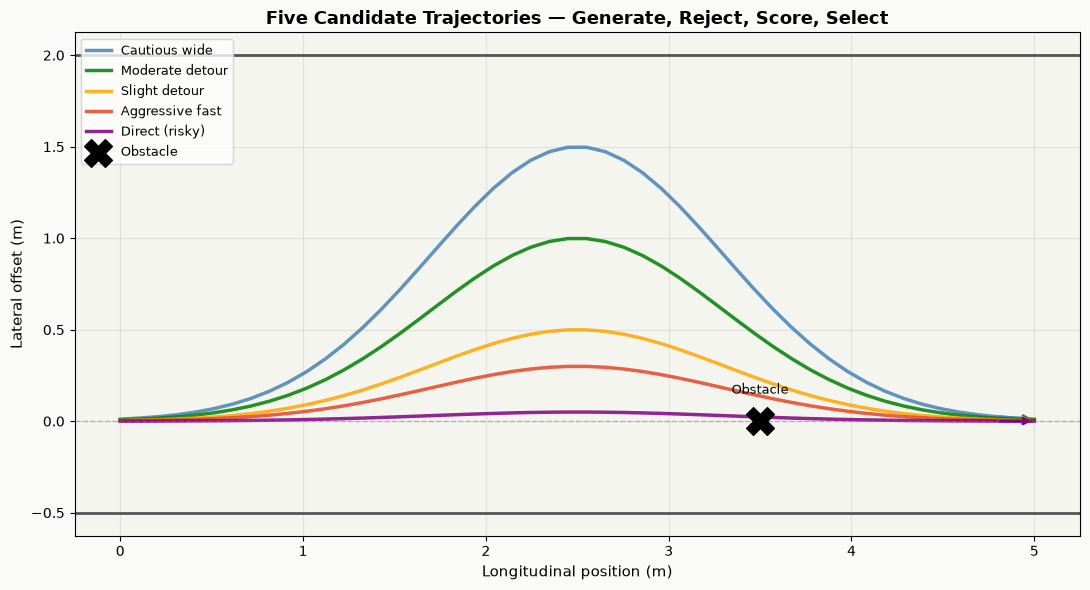

In [16]:
# ── Generate 5 candidate trajectories ─────────────────────────────────────────
# Each trajectory is a numpy array of shape (T, 3): [x, y, speed] at each time step.

T = 50        # time steps
dt = 0.1      # seconds
t  = np.linspace(0, T*dt, T)

OBSTACLE = np.array([3.5, 0.0])  # static obstacle position

def make_trajectory(lateral_offset, peak_speed, smooth=True):
    """Parametric trajectory from x=0 to x=5, with lateral detour."""
    x = np.linspace(0, 5, T)
    # Gaussian lateral bump centred at x=2.5
    y = lateral_offset * np.exp(-0.5 * ((x - 2.5) / 0.8)**2)
    speed = peak_speed * np.sin(np.pi * x / 5)
    if not smooth:
        # Add a jerk spike
        speed[15:20] += np.linspace(0, 1.5, 5)
        speed[20:25] -= np.linspace(1.5, 0, 5)
    return np.stack([x, y, speed], axis=1)

trajectories = [
    ('Cautious wide',    make_trajectory(1.5, 1.5)),
    ('Moderate detour',  make_trajectory(1.0, 2.5)),
    ('Slight detour',    make_trajectory(0.5, 3.0)),
    ('Aggressive fast',  make_trajectory(0.3, 4.5, smooth=False)),
    ('Direct (risky)',   make_trajectory(0.05, 3.5)),
]

fig, ax = plt.subplots(figsize=(11, 6))
ax.set_facecolor('#F5F5F0')
fig.patch.set_facecolor('#FAFAF8')

colors_traj = ['steelblue', 'green', 'orange', USYD_RED, 'purple']
for (name, traj), color in zip(trajectories, colors_traj):
    ax.plot(traj[:, 0], traj[:, 1], lw=2.5, color=color, label=name, alpha=0.85)
    ax.annotate('', xy=(traj[-1, 0], traj[-1, 1]),
                xytext=(traj[-3, 0], traj[-3, 1]),
                arrowprops=dict(arrowstyle='->', color=color, lw=2))

ax.scatter(*OBSTACLE, s=400, color='black', marker='X', zorder=6, label='Obstacle')
ax.text(OBSTACLE[0], OBSTACLE[1]+0.15, 'Obstacle', ha='center', fontsize=9)
ax.axhline(0, color='gray', lw=1, ls='--', alpha=0.5)
ax.axhline(-0.5, color='#555', lw=2, ls='-')   # road boundary
ax.axhline(2.0,  color='#555', lw=2, ls='-')
ax.set_xlabel('Longitudinal position (m)', fontsize=11)
ax.set_ylabel('Lateral offset (m)', fontsize=11)
ax.set_title('Five Candidate Trajectories — Generate, Reject, Score, Select',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# ── Cost functions ─────────────────────────────────────────────────────────────

def progress_cost(traj, v_desired=3.0):
    """J_p: penalise deviation from the desired speed."""
    speeds = traj[:, 2]
    return float(np.mean((speeds - v_desired)**2))

def comfort_cost(traj):
    """J_c: jerk integral (third derivative of position ≈ Δaccel/dt)."""
    speeds = traj[:, 2]
    accel  = np.diff(speeds) / dt
    jerk   = np.diff(accel)  / dt
    return float(np.mean(jerk**2))

def safety_cost(traj, obstacle=OBSTACLE, d_min=0.4):
    """
    J_s: exponential barrier — cost explodes as clearance approaches d_min.
    Returns float('inf') if hard constraint d >= d_min is violated.
    """
    positions = traj[:, :2]
    dists     = np.linalg.norm(positions - obstacle, axis=1)
    if np.any(dists < d_min):
        return float('inf')   # hard constraint violated → reject
    return float(np.mean(np.exp(1.0 / (dists - d_min + 1e-6))))

def score_trajectory(traj, wp, wc, ws):
    """
    Compute the total weighted cost J(π) = wp*Jp + wc*Jc + ws*Js.

    Parameters
    ----------
    traj : np.ndarray, shape (T, 3) — [x, y, speed]
    wp   : float — weight for progress cost
    wc   : float — weight for comfort cost
    ws   : float — weight for safety cost

    Returns
    -------
    total   : float
    details : dict with keys 'Jp', 'Jc', 'Js'
    """
    Jp = progress_cost(traj)
    Jc = comfort_cost(traj)
    Js = safety_cost(traj)
    total = wp * Jp + wc * Jc + ws * Js
    return total, {'Jp': Jp, 'Jc': Jc, 'Js': Js}

# ── Weight policies from the lecture ──────────────────────────────────────────
POLICIES = {
    'School Zone (cautious)':   dict(wp=0.2, wc=0.5, ws=1.5),
    'Highway Merge (assertive)': dict(wp=1.2, wc=0.2, ws=1.0),
}

results = {}
for policy_name, weights in POLICIES.items():
    print(f'\n📋  Policy: {policy_name}  {weights}')
    scores = []
    for name, traj in trajectories:
        total, details = score_trajectory(traj, **weights)
        scores.append((total, name, details))
        status = '✅' if not math.isinf(total) else '🚫'
        print(f'   {status}  {name:22s}  J={total:7.3f}  '
              f'Jp={details["Jp"]:.3f}  Jc={details["Jc"]:.3f}  Js={details["Js"]:.3f}')
    best = min((s for s in scores if not math.isinf(s[0])), key=lambda x: x[0])
    results[policy_name] = (best, scores)
    print(f'   ⭐  Selected: {best[1]}  (J={best[0]:.3f})')


📋  Policy: School Zone (cautious)  {'wp': 0.2, 'wc': 0.5, 'ws': 1.5}
   ✅  Cautious wide           J=869.465  Jp=4.489  Jc=0.194  Js=578.980
   🚫  Moderate detour         J=    inf  Jp=2.707  Jc=0.539  Js=inf
   🚫  Slight detour           J=    inf  Jp=2.184  Jc=0.776  Js=inf
   🚫  Aggressive fast         J=    inf  Jp=2.211  Jc=4806.426  Js=inf
   🚫  Direct (risky)          J=    inf  Jp=1.905  Jc=1.056  Js=inf
   ⭐  Selected: Cautious wide  (J=869.465)

📋  Policy: Highway Merge (assertive)  {'wp': 1.2, 'wc': 0.2, 'ws': 1.0}
   ✅  Cautious wide           J=584.406  Jp=4.489  Jc=0.194  Js=578.980
   🚫  Moderate detour         J=    inf  Jp=2.707  Jc=0.539  Js=inf
   🚫  Slight detour           J=    inf  Jp=2.184  Jc=0.776  Js=inf
   🚫  Aggressive fast         J=    inf  Jp=2.211  Jc=4806.426  Js=inf
   🚫  Direct (risky)          J=    inf  Jp=1.905  Jc=1.056  Js=inf
   ⭐  Selected: Cautious wide  (J=584.406)


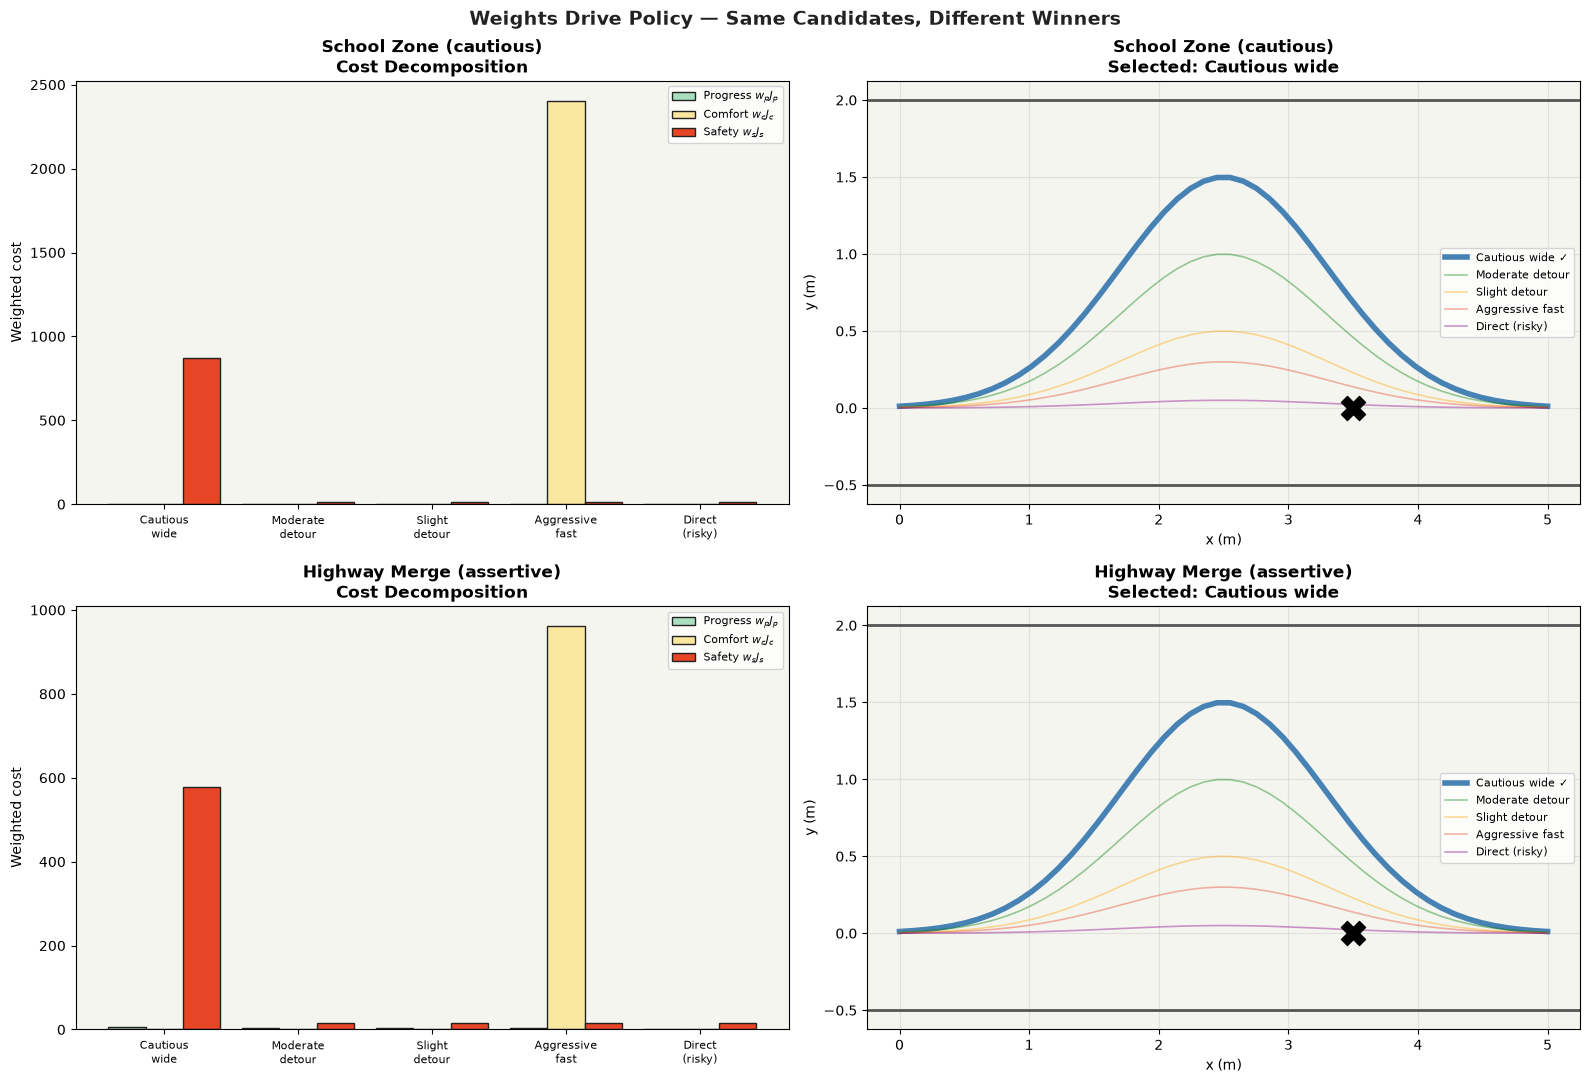

In [18]:
# ── Visualise cost breakdown for both policies ─────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for row_idx, (policy_name, weights) in enumerate(POLICIES.items()):
    ax_bar   = axes[row_idx][0]
    ax_traj  = axes[row_idx][1]

    _, all_scores = results[policy_name]
    names  = [s[1] for s in all_scores]
    Jps    = [s[2]['Jp'] * weights['wp'] for s in all_scores]
    Jcs    = [s[2]['Jc'] * weights['wc'] for s in all_scores]
    Jss    = [s[2]['Js'] * weights['ws'] if not math.isinf(s[0]) else 15 for s in all_scores]

    x   = np.arange(len(names))
    bar_w = 0.28
    ax_bar.bar(x - bar_w, Jps, bar_w, label='Progress $w_p J_p$', color=PALE_GREE,  ec=USYD_DARK)
    ax_bar.bar(x,         Jcs, bar_w, label='Comfort $w_c J_c$',  color=PALE_YELL,  ec=USYD_DARK)
    ax_bar.bar(x + bar_w, Jss, bar_w, label='Safety $w_s J_s$',   color=USYD_RED,   ec=USYD_DARK)
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels([n.replace(' ', '\n') for n in names], fontsize=8)
    ax_bar.set_title(f'{policy_name}\nCost Decomposition', fontweight='bold')
    ax_bar.legend(fontsize=8)
    ax_bar.set_ylabel('Weighted cost')
    ax_bar.set_facecolor('#F5F5F0')

    # Trajectory panel
    best_name = results[policy_name][0][1]
    ax_traj.set_facecolor('#F5F5F0')
    for (name, traj), color in zip(trajectories, colors_traj):
        lw    = 4.0  if name == best_name else 1.2
        alpha = 1.0  if name == best_name else 0.4
        ax_traj.plot(traj[:, 0], traj[:, 1], lw=lw, color=color,
                     label=f'{name} ✓' if name == best_name else name, alpha=alpha)
    ax_traj.scatter(*OBSTACLE, s=300, color='black', marker='X', zorder=6)
    ax_traj.axhline(-0.5, color='#555', lw=2)
    ax_traj.axhline(2.0,  color='#555', lw=2)
    ax_traj.set_title(f'{policy_name}\nSelected: {best_name}', fontweight='bold')
    ax_traj.legend(fontsize=8)
    ax_traj.grid(alpha=0.3)
    ax_traj.set_xlabel('x (m)'); ax_traj.set_ylabel('y (m)')

plt.suptitle('Weights Drive Policy — Same Candidates, Different Winners',
             fontsize=14, fontweight='bold', color=USYD_DARK)
plt.tight_layout()
plt.show()

---
## 🎲 Section 4 — Decision Under Uncertainty: MDP & Risk Shadows  *(Optional C — not marked)*

Deterministic planners fail when perception is noisy. An **MDP** replaces guaranteed transitions with probabilities:

$$\mathbb{E}[J \mid a] = \sum_{s'} P(s' \mid s, a) \cdot J(s')$$

We solve the 5×5 grid world from the lecture using **value iteration**, then visualise how slip probabilities create *risk shadows* near hazards.

In [19]:
# ── Grid world setup ───────────────────────────────────────────────────────────
GRID_SIZE = 5
GOAL_CELL = (4, 4)  # bottom-right
HAZARD    = (2, 2)  # central hazard (high penalty)
WALL      = (1, 3)  # blocked cell

ACTIONS = {
    'UP':    (-1,  0),
    'DOWN':  ( 1,  0),
    'LEFT':  ( 0, -1),
    'RIGHT': ( 0,  1),
}
ACTION_PERP = {
    'UP':    [('LEFT',0.5),('RIGHT',0.5)],
    'DOWN':  [('LEFT',0.5),('RIGHT',0.5)],
    'LEFT':  [('UP',0.5),  ('DOWN',0.5)],
    'RIGHT': [('UP',0.5),  ('DOWN',0.5)],
}

def in_grid(r, c):
    return 0 <= r < GRID_SIZE and 0 <= c < GRID_SIZE

def step(r, c, action_name, dr, dc):
    """Return (next_r, next_c) clamping at walls."""
    nr, nc = r + dr, c + dc
    if not in_grid(nr, nc) or (nr, nc) == WALL:
        return r, c   # bounce back
    return nr, nc

def get_reward(r, c):
    if (r, c) == GOAL_CELL:  return  10.0
    if (r, c) == HAZARD:     return -10.0
    if (r, c) == WALL:       return   0.0
    return -0.1   # small movement penalty encourages efficiency

def transitions(r, c, action_name, p_intended=0.8):
    """
    Stochastic transition: 80% intended direction, 10% each perpendicular.
    Returns list of (probability, next_r, next_c).
    """
    dr, dc = ACTIONS[action_name]
    p_side = (1 - p_intended) / 2
    outcomes = []
    nr, nc = step(r, c, action_name, dr, dc)
    outcomes.append((p_intended, nr, nc))
    for side_name, _ in ACTION_PERP[action_name]:
        sdr, sdc = ACTIONS[side_name]
        snr, snc = step(r, c, side_name, sdr, sdc)
        outcomes.append((p_side, snr, snc))
    return outcomes

print('✅  MDP grid world configured — 5×5 grid')
print(f'   Goal: {GOAL_CELL}  |  Hazard: {HAZARD}  |  Wall: {WALL}')

✅  MDP grid world configured — 5×5 grid
   Goal: (4, 4)  |  Hazard: (2, 2)  |  Wall: (1, 3)


In [20]:
def value_iteration(p_intended=0.8, gamma=0.9, theta=1e-6, max_iter=500):
    """
    Solve the MDP using value iteration.

    V^*(s) = max_a Σ_{s'} P(s'|s,a) [ R(s') + γ V^*(s') ]

    Parameters
    ----------
    p_intended : float — probability of intended move (slip = 1-p).
    gamma      : float — discount factor.
    theta      : float — convergence threshold.
    max_iter   : int   — safety cap on iterations.

    Returns
    -------
    V      : np.ndarray (GRID_SIZE, GRID_SIZE) — optimal value function.
    policy : dict {(r,c): best_action_name}    — greedy policy.
    """
    V = np.zeros((GRID_SIZE, GRID_SIZE))
    V[GOAL_CELL] = 10.0

    for iteration in range(max_iter):
        delta = 0.0
        V_new = V.copy()
        for r in range(GRID_SIZE):
            for c in range(GRID_SIZE):
                if (r, c) in (GOAL_CELL, WALL):
                    continue
                action_values = []
                for action_name in ACTIONS:
                    q = sum(
                        p * (get_reward(nr, nc) + gamma * V[nr, nc])
                        for p, nr, nc in transitions(r, c, action_name, p_intended)
                    )
                    action_values.append(q)
                V_new[r, c] = max(action_values)
                delta = max(delta, abs(V_new[r, c] - V[r, c]))
        V = V_new
        if delta < theta:
            print(f'   Converged in {iteration+1} iterations (Δ={delta:.2e})')
            break

    # Extract greedy policy
    policy = {}
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if (r, c) in (GOAL_CELL, WALL):
                continue
            best_a, best_q = None, -float('inf')
            for action_name in ACTIONS:
                q = sum(
                    p * (get_reward(nr, nc) + gamma * V[nr, nc])
                    for p, nr, nc in transitions(r, c, action_name, p_intended)
                )
                if q > best_q:
                    best_q, best_a = q, action_name
            policy[(r, c)] = best_a

    return V, policy

print('Running value iteration for p_intended=0.8 (lecture scenario) ...')
V_80, policy_80 = value_iteration(p_intended=0.8)
print('Running value iteration for p_intended=0.5 (high uncertainty) ...')
V_50, policy_50 = value_iteration(p_intended=0.5)

Running value iteration for p_intended=0.8 (lecture scenario) ...
   Converged in 32 iterations (Δ=4.99e-07)
Running value iteration for p_intended=0.5 (high uncertainty) ...
   Converged in 61 iterations (Δ=7.89e-07)


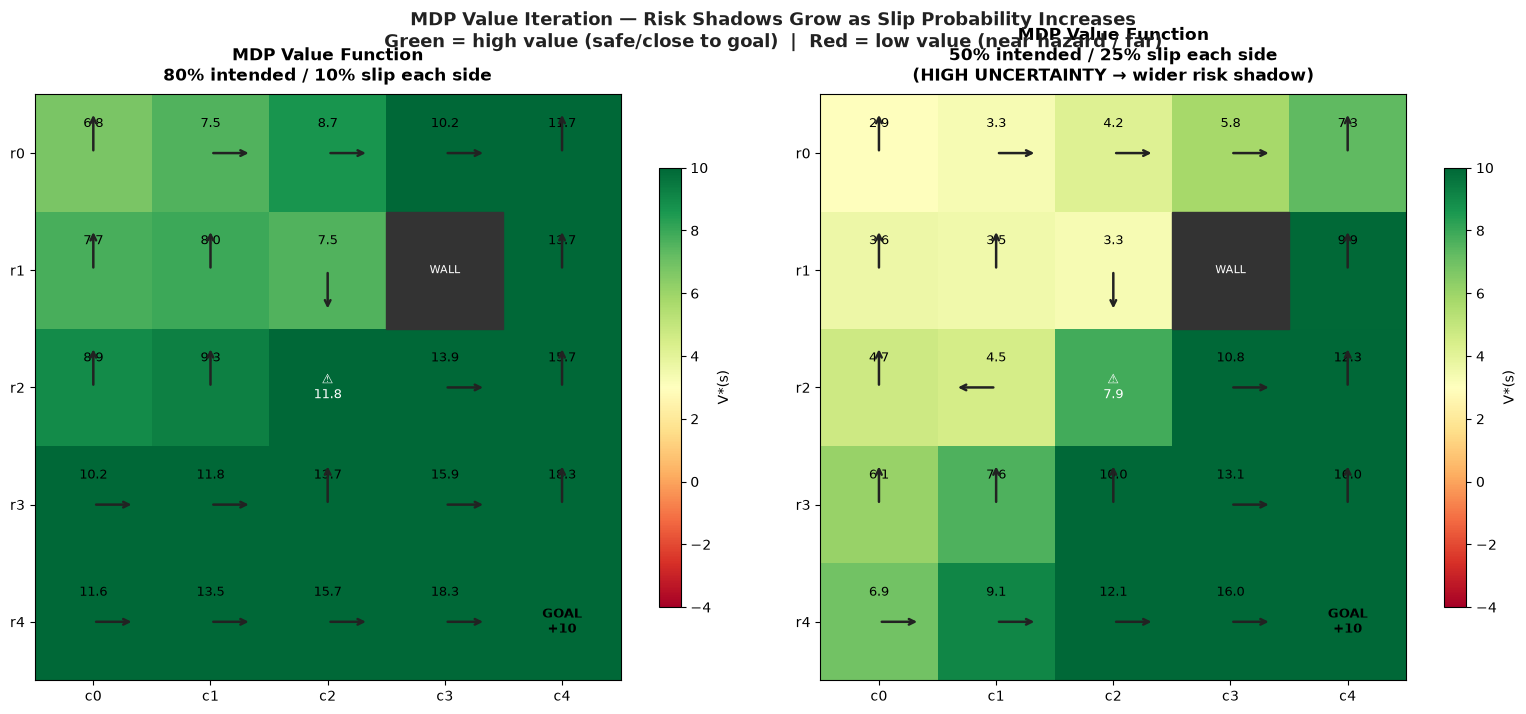

In [21]:
# ── Visualise value functions & risk shadows ───────────────────────────────────

ARROW_MAP = {'UP': (0, 0.35), 'DOWN': (0, -0.35), 'LEFT': (-0.35, 0), 'RIGHT': (0.35, 0)}

def plot_mdp(V, policy, title, ax):
    im = ax.imshow(V, cmap='RdYlGn', vmin=-4, vmax=10, origin='upper')
    ax.set_facecolor('#222')

    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            v = V[r, c]
            text_color = 'black' if v > 0 else 'white'

            if (r, c) == GOAL_CELL:
                ax.text(c, r, 'GOAL\n+10', ha='center', va='center',
                        fontsize=9, fontweight='bold', color='black')
            elif (r, c) == HAZARD:
                ax.text(c, r, f'⚠️\n{v:.1f}', ha='center', va='center',
                        fontsize=9, color='white')
            elif (r, c) == WALL:
                ax.add_patch(plt.Rectangle((c-0.5, r-0.5), 1, 1, color='#333'))
                ax.text(c, r, 'WALL', ha='center', va='center', fontsize=8, color='white')
            else:
                ax.text(c, r - 0.25, f'{v:.1f}', ha='center', va='center',
                        fontsize=9, color=text_color)
                if (r, c) in policy:
                    dx, dy = ARROW_MAP[policy[(r, c)]]
                    ax.annotate('', xy=(c+dx, r+dy), xytext=(c, r),
                                arrowprops=dict(arrowstyle='->', color='#222', lw=1.8))

    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.set_xticklabels([f'c{i}' for i in range(GRID_SIZE)])
    ax.set_yticklabels([f'r{i}' for i in range(GRID_SIZE)])
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    return im

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
im1 = plot_mdp(V_80, policy_80, 'MDP Value Function\n80% intended / 10% slip each side', axes[0])
im2 = plot_mdp(V_50, policy_50, 'MDP Value Function\n50% intended / 25% slip each side\n(HIGH UNCERTAINTY → wider risk shadow)', axes[1])

plt.colorbar(im1, ax=axes[0], shrink=0.75, label='V*(s)')
plt.colorbar(im2, ax=axes[1], shrink=0.75, label='V*(s)')

plt.suptitle('MDP Value Iteration — Risk Shadows Grow as Slip Probability Increases\n'
             'Green = high value (safe/close to goal)  |  Red = low value (near hazard / far)',
             fontsize=13, fontweight='bold', color=USYD_DARK)
plt.tight_layout()
plt.show()

   Converged in 21 iterations (Δ=1.76e-07)
   Converged in 32 iterations (Δ=4.99e-07)
   Converged in 50 iterations (Δ=8.74e-07)
   Converged in 61 iterations (Δ=7.89e-07)


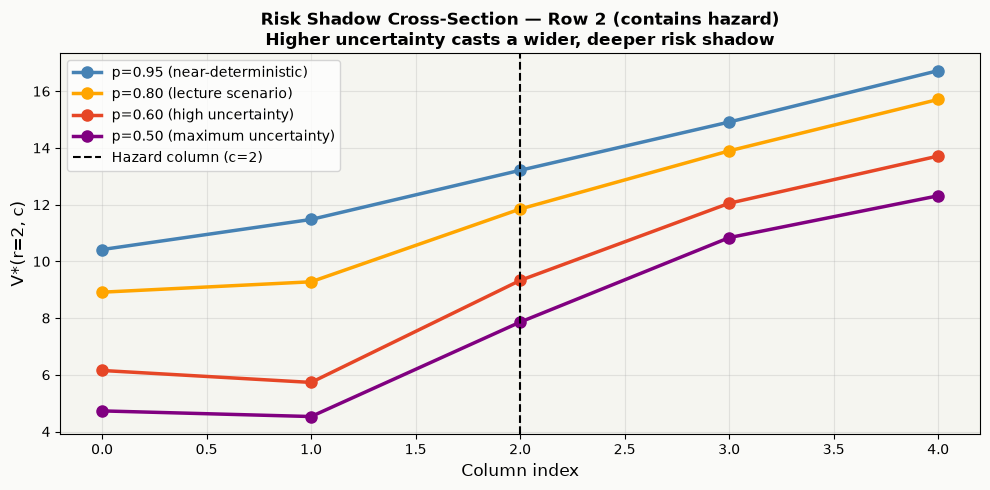


💡  Notice how adjacent cells to the hazard drop in value as slip probability increases.
    The MDP encodes the RISK of being near danger even before an incident occurs.


In [22]:
# ── Risk shadow cross-section ──────────────────────────────────────────────────
# Show how value along the row containing the hazard changes with slip probability.

fig, ax = plt.subplots(figsize=(10, 5))

hazard_row = HAZARD[0]
for p_int, color, label in [
    (0.95, 'steelblue', 'p=0.95 (near-deterministic)'),
    (0.80, 'orange',    'p=0.80 (lecture scenario)'),
    (0.60, USYD_RED,    'p=0.60 (high uncertainty)'),
    (0.50, 'purple',    'p=0.50 (maximum uncertainty)'),
]:
    V_p, _ = value_iteration(p_intended=p_int)
    ax.plot(range(GRID_SIZE), V_p[hazard_row, :], 'o-', color=color,
            lw=2.5, markersize=8, label=label)

ax.axvline(HAZARD[1], color='black', ls='--', lw=1.5, label=f'Hazard column (c={HAZARD[1]})')
ax.set_xlabel('Column index', fontsize=12)
ax.set_ylabel(f'V*(r={hazard_row}, c)', fontsize=12)
ax.set_title(f'Risk Shadow Cross-Section — Row {hazard_row} (contains hazard)\n'
             'Higher uncertainty casts a wider, deeper risk shadow',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_facecolor('#F5F5F0')
fig.patch.set_facecolor('#FAFAF8')
plt.tight_layout()
plt.show()

print('\n💡  Notice how adjacent cells to the hazard drop in value as slip probability increases.')
print('    The MDP encodes the RISK of being near danger even before an incident occurs.')

### 📝 Reflection — Sections 2, 3 & 4

1. **(FSM)** What happens to the number of required transitions when you add a `ROADWORK` state that overlaps with all existing states? Try it.
2. **(Motion)** What weight ratio $w_s / w_p$ makes the cautious policy select the same trajectory as the aggressive policy?
3. **(MDP)** Why does the risk shadow appear in cells that are *not* the hazard itself? What does this mean for a real autonomous vehicle?
4. **(MDP)** What happens if $\gamma \to 0$? What about $\gamma \to 1$? Try both in `value_iteration`.
5. **(Integration)** Trace the full pipeline — Route (A*) → Behaviour (FSM) → Motion (scoring) → Uncertainty (MDP) — for the scenario: *"Vehicle is at node A, goal is node J, a pedestrian is crossing at node E."*

*Write your answers here...*

---

---
## 🏎️ Section 5 — Simulation Challenge *(Optional D — Extra Marks)*

> **This task carries bonus marks assessed separately. See Gradescope for the submission field.**

Apply one or more of the planning algorithms from this lab (Dijkstra, A*, FSM, MDP) inside a physics-based driving simulator.

### Suggested environments

| Environment | Install | Suggested task |
|---|---|---|
| [`highway-env`](https://github.com/Farama-Foundation/HighwayEnv) | `pip install highway-env` | A\* lane selection on `highway-v0` or FSM in `intersection-v0` |
| [SUMO](https://sumo.dlr.de) | separate install | Route planning with Dijkstra/A* on a real OSM-imported network |

### Deliverable
1. Record a simulation video (≥ 30 s showing your planner in action).
2. Upload your video in Canvas.
3. Also, put your explanation in Canvas: (a) which algorithm you applied, (b) how you encoded the planning layer, and (c) one limitation you observed.

### Starter code — `highway-env`
> _Warning_: It will take considerable time to complete this part.

In [23]:
# %pip install --quiet highway-env moviepy

In [24]:
# # ── Optional D Starter — highway-env ──────────────────────────────────────────
# # Install:  pip install highway-env moviepy
# # Uncomment and run after installing.

# import gymnasium as gym
# import highway_env  # This import is required to register custom environments like 'intersection-v0'!

# env = gym.make(
#     'intersection-v0',
#     render_mode='rgb_array',
#     config={
#         'observation': {'type': 'Kinematics'},
#         'action':      {'type': 'DiscreteMetaAction'},
#         'duration':    20,
#         'vehicles_count': 5,
#     }
# )

# # ── YOUR PLANNER HERE ──────────────────────────────────────────────────────
# def my_planner(obs):
#     """
#     Replace this with your FSM / A* / MDP policy.
#     obs: numpy array of vehicle kinematics from the environment.
#     Returns: integer action index.
#     """
#     return env.action_space.sample()   # ← replace with your logic
# # ── END YOUR PLANNER ───────────────────────────────────────────────────────

# frames = []
# obs, _ = env.reset()
# for _ in range(200):
#     action = my_planner(obs)
#     obs, reward, terminated, truncated, info = env.step(action)
#     frames.append(env.render())
#     if terminated or truncated:
#         obs, _ = env.reset()
# env.close()

# # Save frames as MP4
# import imageio
# imageio.mimsave('my_planner.mp4', frames, fps=15)
# print('✅  Video saved to my_planner.mp4 — upload to YouTube and paste URL below.')

# print('Install highway-env and uncomment the starter code above to begin.')

---
## 🧩 Full Pipeline Summary

The cell below brings the whole lecture hierarchy to life on the running example — all four layers in sequence.

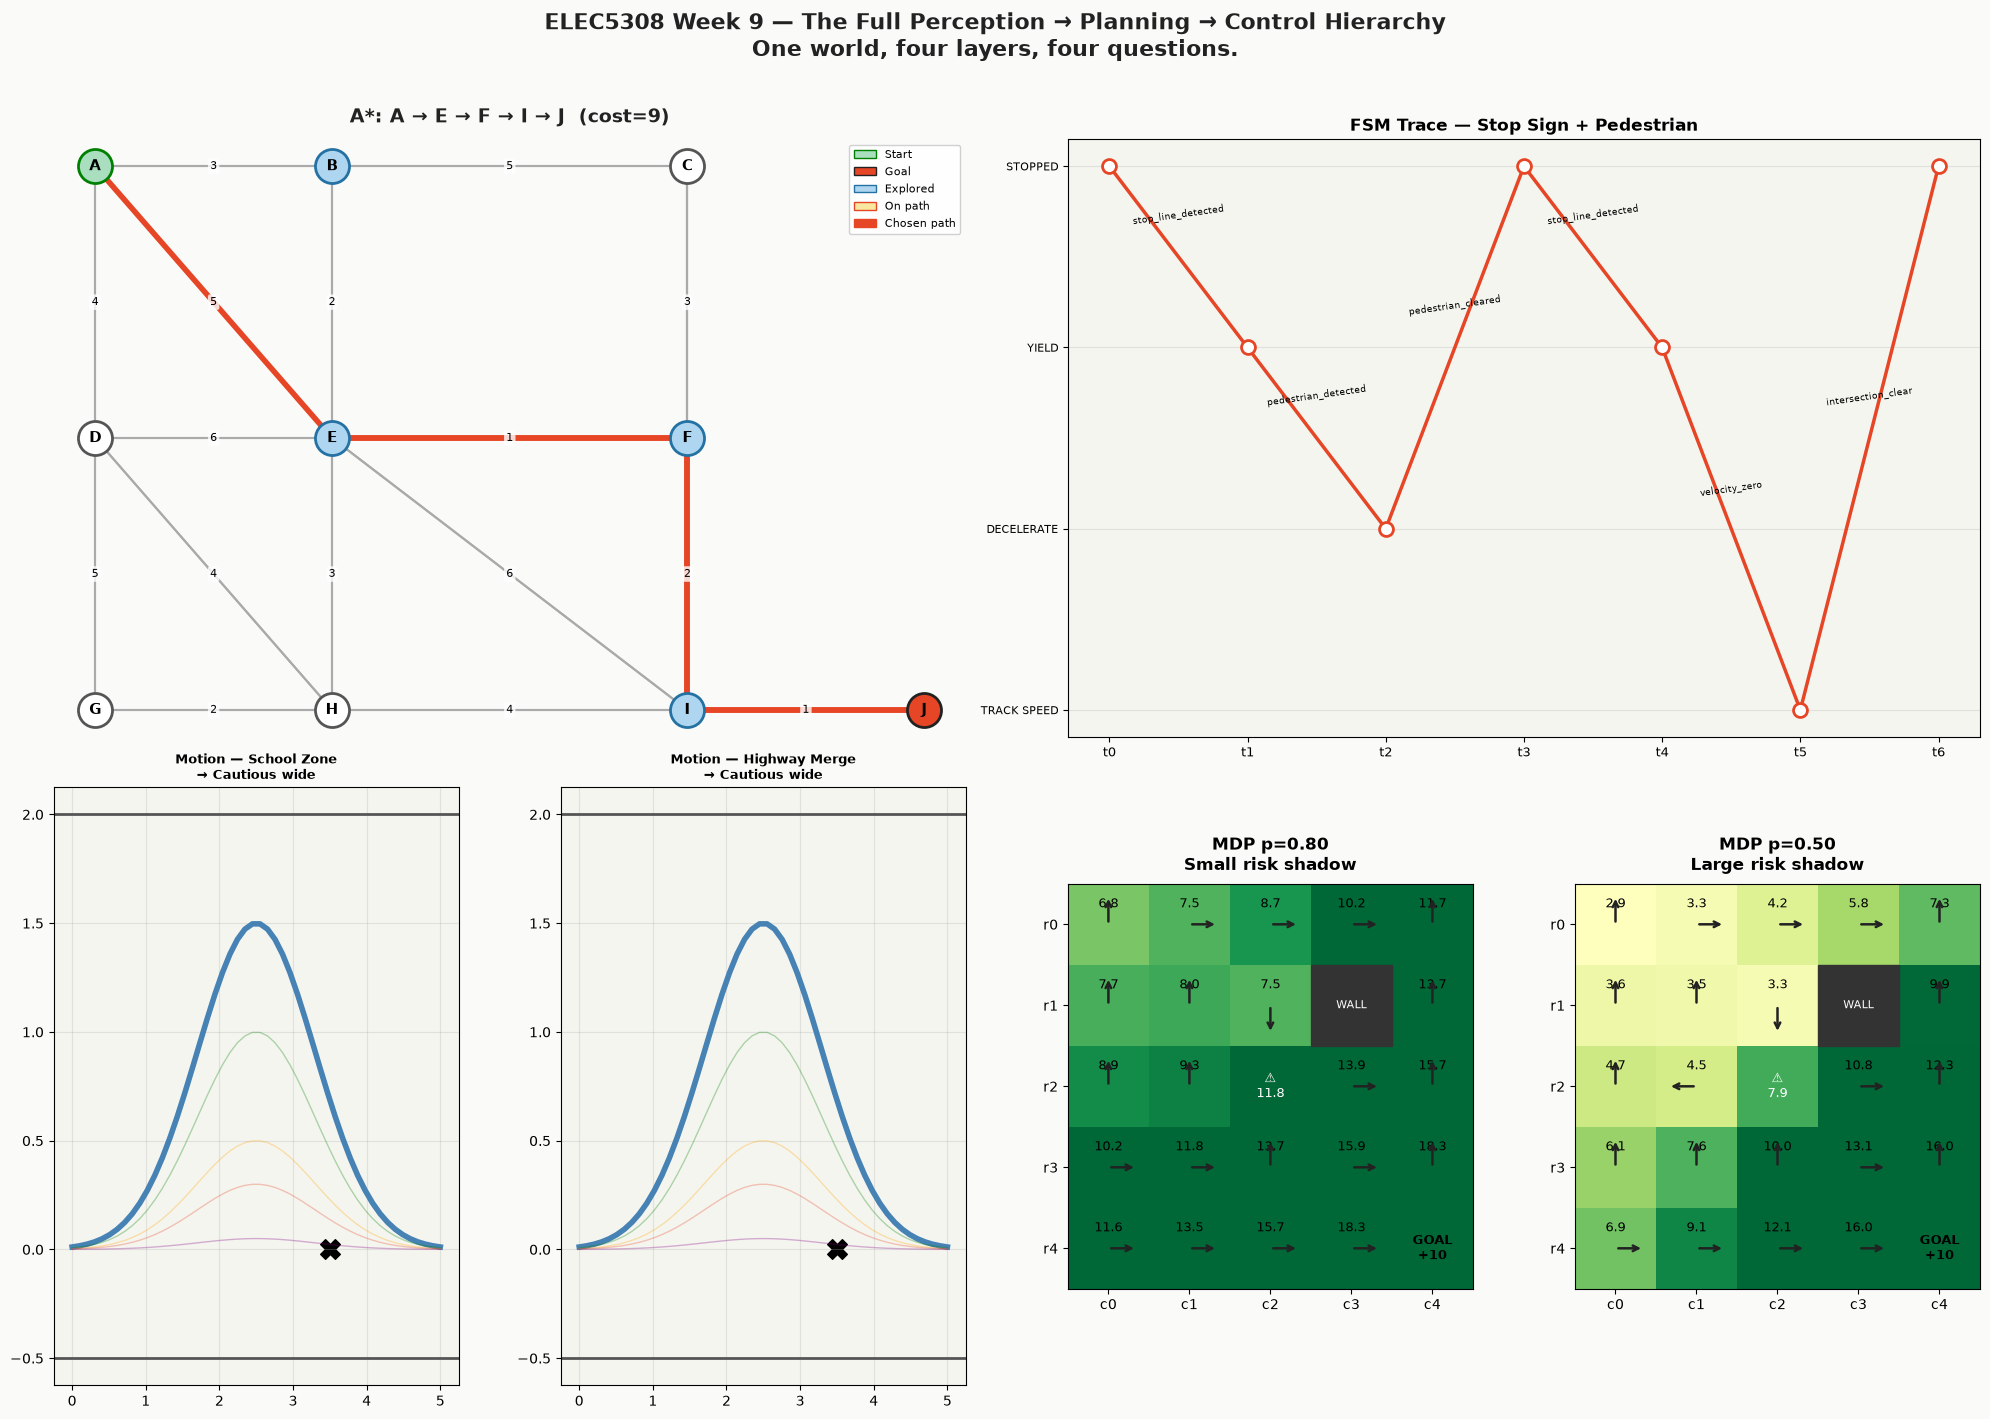

In [25]:
# ── Full pipeline summary figure ───────────────────────────────────────────────

try:
    dij_path, dij_cost, dij_explored = dijkstra(GRAPH, START, GOAL)
    astar_path, astar_cost, astar_explored = a_star(GRAPH, START, GOAL, euclidean_heuristic)

    fig = plt.figure(figsize=(20, 14))
    fig.patch.set_facecolor('#FAFAF8')

    # Layer labels
    layer_labels = [
        'Layer 1:\nRoute Planning (A*)',
        'Layer 2:\nBehaviour (FSM)',
        'Layer 3:\nMotion Planning',
        'Layer 4:\nUncertainty (MDP)'
    ]
    layer_colors = [PALE_GREE, PALE_YELL, PALE_BLUE, '#F1948A']

    # ── Row 0: Route planning ──────────────────────────────────────────────────
    ax1 = fig.add_subplot(2, 4, (1, 2))
    draw_graph(GRAPH, NODE_COORDS, path=astar_path,
               explored=set(astar_explored),
               title=f'A*: {" → ".join(astar_path)}  (cost={astar_cost})',
               ax=ax1)

    # ── Row 0: FSM trace ───────────────────────────────────────────────────────
    ax2 = fig.add_subplot(2, 4, (3, 4))
    ax2.set_facecolor('#F5F5F0')
    state_to_y = {State.TRACK_SPEED: 3, State.DECELERATE: 2, State.YIELD: 1, State.STOPPED: 0}
    xs = list(range(len(history)))
    ys = [state_to_y[s] for s in history]
    ax2.plot(xs, ys, 'o-', color=USYD_RED, lw=2.5, markersize=10,
             markerfacecolor='white', markeredgecolor=USYD_RED, markeredgewidth=2)
    for i, ev in enumerate(events):
        ax2.text((xs[i]+xs[i+1])/2, (ys[i]+ys[i+1])/2+0.18, ev, fontsize=6.5,
                 ha='center', rotation=8)
    ax2.set_yticks(list(state_to_y.values()))
    ax2.set_yticklabels(['STOPPED','YIELD','DECELERATE','TRACK SPEED'], fontsize=8)
    ax2.set_xticks(xs)
    ax2.set_xticklabels([f't{i}' for i in xs], fontsize=9)
    ax2.set_title('FSM Trace — Stop Sign + Pedestrian', fontweight='bold')
    ax2.grid(axis='y', alpha=0.3)

    # ── Row 1: Best trajectory under both policies ─────────────────────────────
    ax3 = fig.add_subplot(2, 4, 5)
    ax3.set_facecolor('#F5F5F0')
    for (name, traj), color in zip(trajectories, colors_traj):
        best_name = results['School Zone (cautious)'][0][1]
        lw    = 4   if name == best_name else 1
        alpha = 1.0 if name == best_name else 0.3
        ax3.plot(traj[:,0], traj[:,1], lw=lw, color=color, alpha=alpha)
    ax3.scatter(*OBSTACLE, s=200, color='k', marker='X')
    ax3.axhline(-0.5, color='#555', lw=2); ax3.axhline(2.0, color='#555', lw=2)
    ax3.set_title(f'Motion — School Zone\n→ {results["School Zone (cautious)"][0][1]}',
                  fontweight='bold', fontsize=9)
    ax3.grid(alpha=0.3)

    ax4 = fig.add_subplot(2, 4, 6)
    ax4.set_facecolor('#F5F5F0')
    for (name, traj), color in zip(trajectories, colors_traj):
        best_name = results['Highway Merge (assertive)'][0][1]
        lw    = 4   if name == best_name else 1
        alpha = 1.0 if name == best_name else 0.3
        ax4.plot(traj[:,0], traj[:,1], lw=lw, color=color, alpha=alpha)
    ax4.scatter(*OBSTACLE, s=200, color='k', marker='X')
    ax4.axhline(-0.5, color='#555', lw=2); ax4.axhline(2.0, color='#555', lw=2)
    ax4.set_title(f'Motion — Highway Merge\n→ {results["Highway Merge (assertive)"][0][1]}',
                  fontweight='bold', fontsize=9)
    ax4.grid(alpha=0.3)

    # ── Row 1: MDP value functions ─────────────────────────────────────────────
    ax5 = fig.add_subplot(2, 4, 7)
    plot_mdp(V_80, policy_80, 'MDP p=0.80\nSmall risk shadow', ax5)

    ax6 = fig.add_subplot(2, 4, 8)
    plot_mdp(V_50, policy_50, 'MDP p=0.50\nLarge risk shadow', ax6)

    plt.suptitle(
        'ELEC5308 Week 9 — The Full Perception → Planning → Control Hierarchy\n'
        'One world, four layers, four questions.',
        fontsize=16, fontweight='bold', color=USYD_DARK, y=1.01
    )
    plt.tight_layout()
    plt.show()

except NotImplementedError:
    print('⚠️  Complete the mandatory dijkstra() and a_star() implementations to render the summary.')

---

## 📤 Submission Checklist

Before submitting to Gradescope:

- [ ] `dijkstra()` implemented and tested on at least 3 different (start, goal) pairs.
- [ ] `a_star()` implemented with the Euclidean heuristic and verified against Dijkstra.
- [ ] All cells above **Restart & Run All** without errors.

Submit GitHub on Gradescope.
